<a href="https://colab.research.google.com/github/kennethdave005-star/INDEXING-TOOLS/blob/main/Stage_2_Applied_Pareto_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 2 — Applied Pareto Analysis (Individual)
## UCI Online Retail Dataset

**Deliverables:** reproducible analysis, charts, and a 500-word memo generated from the actual results.

**Dataset source:** Chen, D. (2015), *Online Retail*, UCI Machine Learning Repository, DOI: 10.24432/C5BW33. License: CC BY 4.0.  
Official page: https://archive.ics.uci.edu/dataset/352/online+retail

### Research questions
1. What percentage of customers generates 80% of revenue?
2. What percentage of products generates 80% of revenue, and which five products lead?
3. How many countries account for 80% of revenue, and what is the UK's share?
4. Is customer concentration stable month by month, especially in November–December?
5. How does customer concentration change after removing suspected wholesale customers?

### Method and assumptions
- Revenue is calculated as `Quantity × UnitPrice`.
- Rows with cancelled invoices (InvoiceNo begins with `C`) are excluded, as are rows with non-positive quantity or price, to estimate completed positive sales. The notebook reports how many rows are excluded.
- Customer-level analysis excludes rows with missing CustomerID. Product and country analyses use valid positive sales rows and do not require CustomerID.
- For a Pareto ratio, the notebook reports the smallest number of ranked entities whose cumulative revenue reaches or exceeds 80%, divided by the total number of entities.
- Wholesale flag: for each customer, calculate mean order value across invoices. A customer is flagged when their average order value is strictly greater than 10 times the median customer average order value. The top 5% spenders are also reported separately. This is an operational heuristic, not proof that a customer is a wholesaler.
- Monthly stability uses each month's customer revenue distribution and reports the share of customers needed to reach 80% of that month's revenue. Customers with no purchases in a given month are not counted in that month's customer base.

Run all cells from top to bottom. The notebook downloads the official dataset when possible. If automatic download is blocked, download `Online Retail.xlsx` from the official UCI page and place it beside this notebook.

## 1. Setup and load the dataset

In [ ]:
# If needed, install dependencies in your notebook environment:
# %pip install pandas numpy matplotlib openpyxl requests

from pathlib import Path
import io, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

DATA_FILE = Path("Online Retail.xlsx")
ZIP_FILE = Path("online_retail.zip")

def load_online_retail():
    # Prefer a local copy so the notebook remains usable offline.
    if DATA_FILE.exists():
        print(f"Loading local file: {DATA_FILE.resolve()}")
        return pd.read_excel(DATA_FILE)

    # Official UCI downloadable archive. UCI's current file is a ZIP containing the Excel workbook.
    urls = [
        "https://archive.ics.uci.edu/static/public/352/online+retail.zip",
        "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx",
    ]
    last_error = None
    for url in urls:
        try:
            print("Attempting official UCI download...")
            with urllib.request.urlopen(url, timeout=60) as response:
                payload = response.read()
            if url.lower().endswith(".zip") or payload[:2] == b"PK":
                with zipfile.ZipFile(io.BytesIO(payload)) as zf:
                    excel_names = [n for n in zf.namelist() if n.lower().endswith(".xlsx")]
                    if not excel_names:
                        raise ValueError("The downloaded ZIP did not contain an XLSX file.")
                    with zf.open(excel_names[0]) as f:
                        return pd.read_excel(f)
            return pd.read_excel(io.BytesIO(payload))
        except Exception as exc:
            last_error = exc
            print(f"Download attempt failed: {exc}")

    raise RuntimeError(
        "Could not download the dataset automatically. Download 'Online Retail.xlsx' "
        "from https://archive.ics.uci.edu/dataset/352/online+retail, place it next to "
        "this notebook, and rerun this cell."
    ) from last_error

raw = load_online_retail()
print("Raw shape:", raw.shape)
display(raw.head())
display(raw.dtypes.to_frame("dtype"))

Attempting official UCI download...
Raw shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


## 2. Clean data and define revenue

In [ ]:
required = ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID", "Country"]
missing_cols = [c for c in required if c not in raw.columns]
if missing_cols:
    raise ValueError(f"Expected columns not found: {missing_cols}")

df = raw.copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
df["StockCode"] = df["StockCode"].astype(str).str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

n_raw = len(df)
cancelled = df["InvoiceNo"].str.upper().str.startswith("C", na=False)
positive = (df["Quantity"] > 0) & (df["UnitPrice"] > 0)
valid_dates = df["InvoiceDate"].notna()
valid_items = df["StockCode"].notna() & (df["StockCode"] != "")
sales = df.loc[~cancelled & positive & valid_dates & valid_items].copy()

print(f"Raw rows: {n_raw:,}")
print(f"Rows marked as cancellations: {int(cancelled.sum()):,}")
print(f"Rows retained as positive completed sales: {len(sales):,}")
print(f"Rows excluded from positive-sales analysis: {n_raw-len(sales):,}")
print(f"Positive sales revenue: £{sales['Revenue'].sum():,.2f}")
print("Date range:", sales["InvoiceDate"].min(), "to", sales["InvoiceDate"].max())
print("Missing CustomerID in retained sales:", int(sales["CustomerID"].isna().sum()))
display(sales.head())

Raw rows: 541,909
Rows marked as cancellations: 9,288
Rows retained as positive completed sales: 530,104
Rows excluded from positive-sales analysis: 11,805
Positive sales revenue: £10,666,684.54
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Missing CustomerID in retained sales: 132220


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


## 3. Reusable Pareto functions

In [ ]:
def pareto_table(series, entity_name="Entity"):
    """Sort revenue descending and calculate cumulative revenue/customer share."""
    s = series.dropna()
    s = s[s > 0].sort_values(ascending=False)
    result = s.rename("Revenue").to_frame()
    result.index.name = entity_name
    result["CumulativeRevenue"] = result["Revenue"].cumsum()
    total = result["Revenue"].sum()
    result["RevenueShare"] = result["Revenue"] / total
    result["CumulativeRevenueShare"] = result["CumulativeRevenue"] / total
    result["EntityRank"] = np.arange(1, len(result) + 1)
    result["CumulativeEntityShare"] = result["EntityRank"] / len(result)
    return result

def entities_for_target(pareto, target=0.80):
    if pareto.empty:
        return {"count": 0, "total": 0, "share": np.nan, "revenue_share_reached": np.nan}
    idx = np.flatnonzero(pareto["CumulativeRevenueShare"].to_numpy() >= target)
    count = int(idx[0] + 1) if len(idx) else len(pareto)
    return {
        "count": count,
        "total": len(pareto),
        "share": count / len(pareto),
        "revenue_share_reached": float(pareto.iloc[count-1]["CumulativeRevenueShare"])
    }

def plot_pareto(pareto, title, filename, top_n=40, entity_label="Entities"):
    p = pareto.head(top_n)
    fig, ax1 = plt.subplots(figsize=(11, 6))
    ax1.bar(np.arange(1, len(p)+1), p["Revenue"], color="steelblue")
    ax1.set_xlabel(f"{entity_label} ranked by revenue (top {len(p)} shown)")
    ax1.set_ylabel("Revenue (£)")
    ax1.set_title(title)
    ax2 = ax1.twinx()
    ax2.plot(np.arange(1, len(p)+1), p["CumulativeRevenueShare"]*100, color="darkorange", marker=".", linewidth=2)
    ax2.axhline(80, color="red", linestyle="--", linewidth=1.5, label="80% revenue")
    ax2.set_ylabel("Cumulative revenue (%)")
    ax2.set_ylim(0, 105)
    ax2.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(filename, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Saved chart: {filename}")

## 4. Task 1 — Customer revenue concentration

Customers included: 4,338
Customers needed to reach 80% of revenue: 1,133
Share of customers needed: 26.12%
Revenue share at cutoff: 80.01%
Classic 80/20 benchmark: 20% of customers generate 80% of revenue.
Difference from 20% benchmark: +6.12 percentage points.


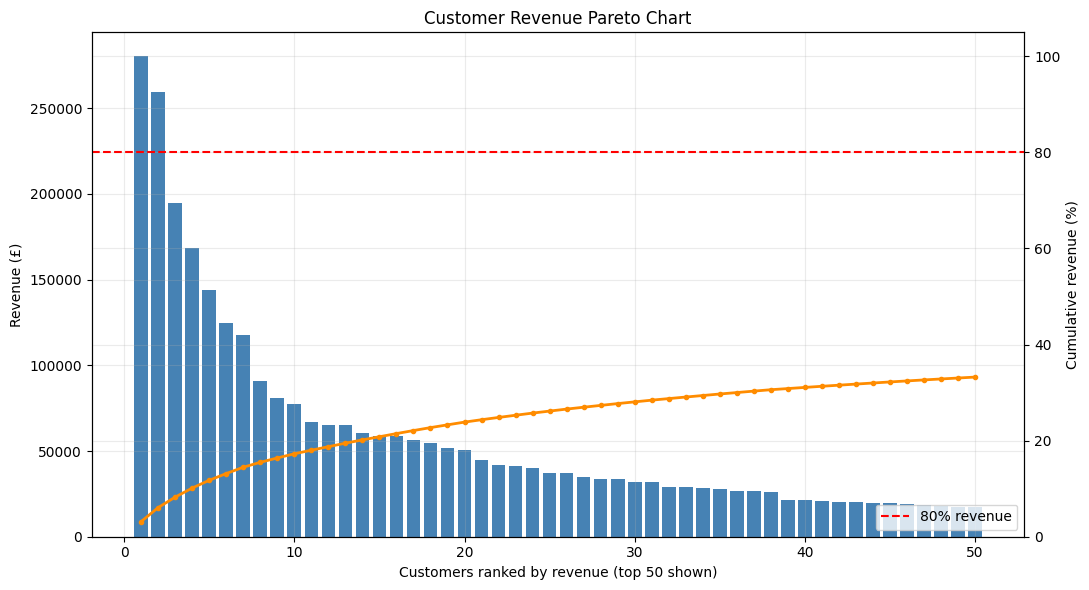

Saved chart: task1_customer_pareto.png


,Revenue,CumulativeRevenue,RevenueShare,CumulativeRevenueShare,EntityRank,CumulativeEntityShare
CustomerID,,,,,,
14646,280206.02,280206.02,0.031444,0.031444,1,0.000231
18102,259657.30,539863.32,0.029138,0.060581,2,0.000461
17450,194550.79,734414.11,0.021832,0.082413,3,0.000692
16446,168472.50,902886.61,0.018905,0.101318,4,0.000922
14911,143825.06,1046711.67,0.016139,0.117457,5,0.001153
12415,124914.53,1171626.20,0.014017,0.131475,6,0.001383
14156,117379.63,1289005.83,0.013172,0.144647,7,0.001614
17511,91062.38,1380068.21,0.010219,0.154865,8,0.001844
16029,81024.84,1461093.05,0.009092,0.163958,9,0.002075


In [ ]:
customer_sales = sales.dropna(subset=["CustomerID"]).copy()
customer_sales["CustomerID"] = customer_sales["CustomerID"].astype(str).str.replace(r"\.0$", "", regex=True)
customer_revenue = customer_sales.groupby("CustomerID")["Revenue"].sum()
customer_pareto = pareto_table(customer_revenue, "CustomerID")
customer_80 = entities_for_target(customer_pareto)

print(f"Customers included: {customer_80['total']:,}")
print(f"Customers needed to reach 80% of revenue: {customer_80['count']:,}")
print(f"Share of customers needed: {customer_80['share']:.2%}")
print(f"Revenue share at cutoff: {customer_80['revenue_share_reached']:.2%}")
print(f"Classic 80/20 benchmark: 20% of customers generate 80% of revenue.")
print(f"Difference from 20% benchmark: {(customer_80['share']-0.20)*100:+.2f} percentage points.")
plot_pareto(customer_pareto, "Customer Revenue Pareto Chart", "task1_customer_pareto.png", top_n=50, entity_label="Customers")
display(customer_pareto.head(10))

## 5. Task 2 — Product revenue concentration

Products included: 3,922
Products needed to reach 80% of revenue: 804
Share of products needed: 20.50%
Revenue share at cutoff: 80.01%


,StockCode,Revenue,Description
3911,DOT,206248.77,DOTCOM POSTAGE
1310,22423,174484.74,REGENCY CAKESTAND 3 TIER
2465,23843,168469.60,"PAPER CRAFT , LITTLE BIRDIE"
3407,85123A,104518.80,WHITE HANGING HEART T-LIGHT HOLDER
2670,47566,99504.33,PARTY BUNTING


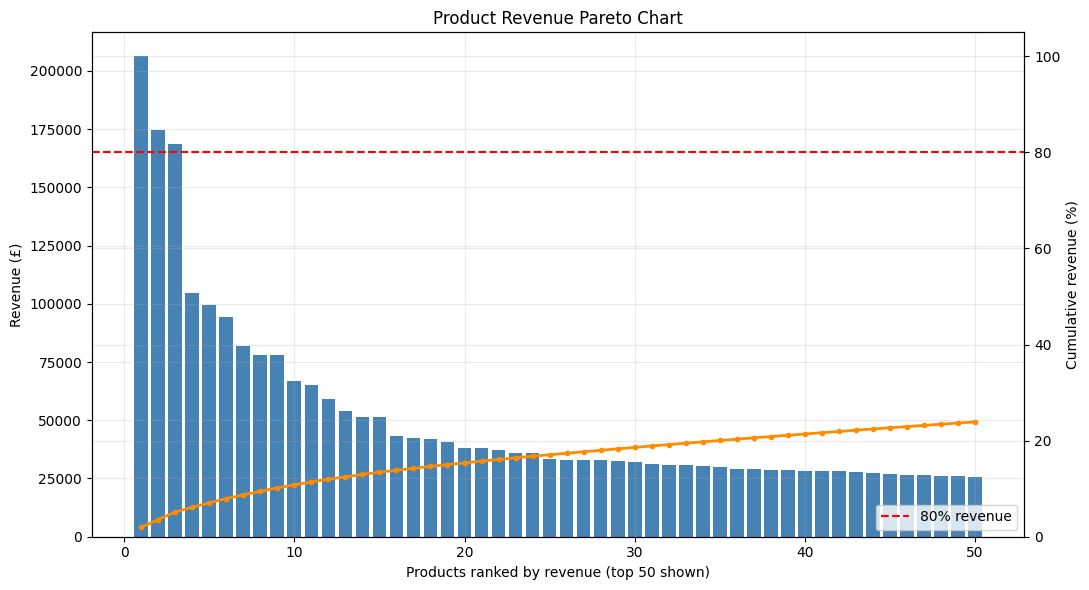

Saved chart: task2_product_pareto.png


,Revenue,CumulativeRevenue,RevenueShare,CumulativeRevenueShare,EntityRank,CumulativeEntityShare
StockCode,,,,,,
DOT,206248.77,206248.77,0.019336,0.019336,1,0.000255
22423,174484.74,380733.51,0.016358,0.035694,2,0.000510
23843,168469.60,549203.11,0.015794,0.051488,3,0.000765
85123A,104518.80,653721.91,0.009799,0.061286,4,0.001020
47566,99504.33,753226.24,0.009329,0.070615,5,0.001275
85099B,94340.05,847566.29,0.008844,0.079459,6,0.001530
23166,81700.92,929267.21,0.007659,0.087119,7,0.001785
M,78110.27,1007377.48,0.007323,0.094441,8,0.002040
POST,78101.88,1085479.36,0.007322,0.101764,9,0.002295


In [ ]:
product_revenue = sales.groupby("StockCode")["Revenue"].sum()
product_pareto = pareto_table(product_revenue, "StockCode")
product_80 = entities_for_target(product_pareto)
print(f"Products included: {product_80['total']:,}")
print(f"Products needed to reach 80% of revenue: {product_80['count']:,}")
print(f"Share of products needed: {product_80['share']:.2%}")
print(f"Revenue share at cutoff: {product_80['revenue_share_reached']:.2%}")

top5_products = (sales.groupby("StockCode", as_index=False)
                 .agg(Revenue=("Revenue", "sum"),
                      Description=("Description", lambda x: x.dropna().mode().iat[0] if not x.dropna().mode().empty else "Unknown"))
                 .sort_values("Revenue", ascending=False).head(5))
top5_products["Revenue"] = top5_products["Revenue"].round(2)
display(top5_products)
plot_pareto(product_pareto, "Product Revenue Pareto Chart", "task2_product_pareto.png", top_n=50, entity_label="Products")
display(product_pareto.head(10))

## 6. Task 3 — Country-level Pareto

Countries included: 38
Countries needed to reach 80% of revenue: 1
Revenue share at cutoff: 84.61%
United Kingdom revenue: £9,025,222.08
UK share of total positive sales revenue: 84.61%


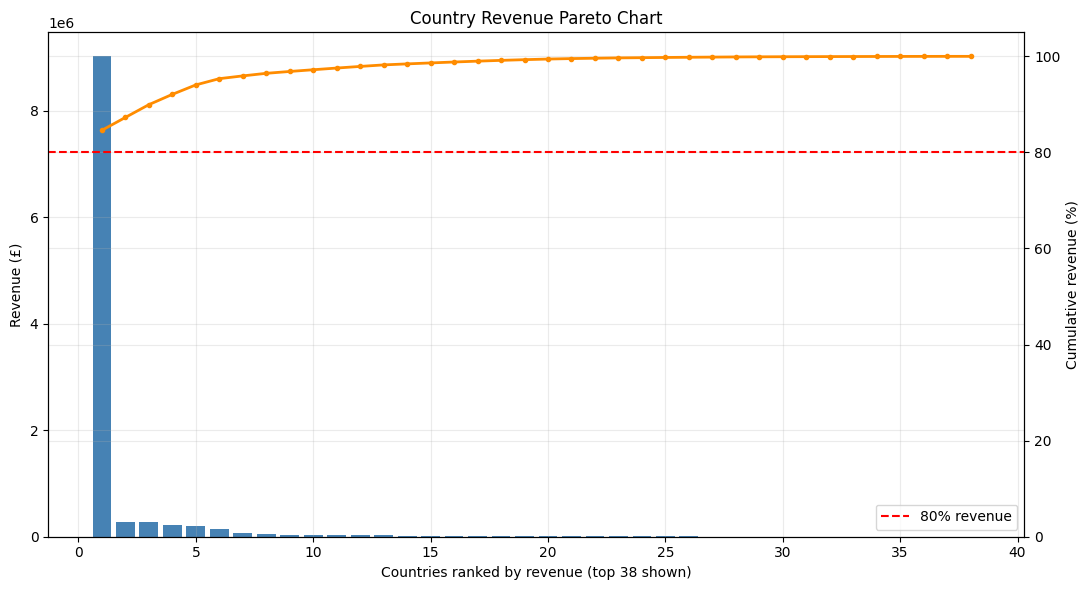

Saved chart: task3_country_pareto.png


,Revenue,CumulativeRevenue,RevenueShare,CumulativeRevenueShare,EntityRank,CumulativeEntityShare
Country,,,,,,
United Kingdom,9025222.084,9.025222e+06,0.846113,0.846113,1,0.026316
Netherlands,285446.340,9.310668e+06,0.026761,0.872874,2,0.052632
EIRE,283453.960,9.594122e+06,0.026574,0.899447,3,0.078947
Germany,228867.140,9.822990e+06,0.021456,0.920904,4,0.105263
France,209715.110,1.003270e+07,0.019661,0.940564,5,0.131579
Australia,138521.310,1.017123e+07,0.012986,0.953551,6,0.157895
Spain,61577.110,1.023280e+07,0.005773,0.959324,7,0.184211
Switzerland,57089.900,1.028989e+07,0.005352,0.964676,8,0.210526
Belgium,41196.340,1.033109e+07,0.003862,0.968538,9,0.236842


In [ ]:
country_revenue = sales.groupby("Country")["Revenue"].sum()
country_pareto = pareto_table(country_revenue, "Country")
country_80 = entities_for_target(country_pareto)
uk_revenue = float(country_revenue.get("United Kingdom", 0.0))
all_country_revenue = float(country_revenue.sum())
uk_share = uk_revenue / all_country_revenue if all_country_revenue else np.nan

print(f"Countries included: {country_80['total']}")
print(f"Countries needed to reach 80% of revenue: {country_80['count']}")
print(f"Revenue share at cutoff: {country_80['revenue_share_reached']:.2%}")
print(f"United Kingdom revenue: £{uk_revenue:,.2f}")
print(f"UK share of total positive sales revenue: {uk_share:.2%}")
plot_pareto(country_pareto, "Country Revenue Pareto Chart", "task3_country_pareto.png", top_n=len(country_pareto), entity_label="Countries")
display(country_pareto)

## 7. Advanced Task 4 — Temporal stability

,Month,Customers,CustomersFor80,CustomerShareFor80,RevenueShareAtCutoff,MonthlyRevenue
0,2010-12,885,369,0.416949,0.800287,572713.890
1,2011-01,741,273,0.368421,0.800334,569445.040
2,2011-02,758,333,0.439314,0.800324,447137.350
3,2011-03,974,424,0.435318,0.800247,595500.760
4,2011-04,856,405,0.473131,0.800511,469200.361
5,2011-05,1056,466,0.441288,0.800481,678594.560
6,2011-06,991,391,0.394551,0.800234,661213.690
7,2011-07,949,404,0.425711,0.800250,600091.011
8,2011-08,935,376,0.402139,0.800480,645343.900
9,2011-09,1266,526,0.415482,0.800190,952838.382


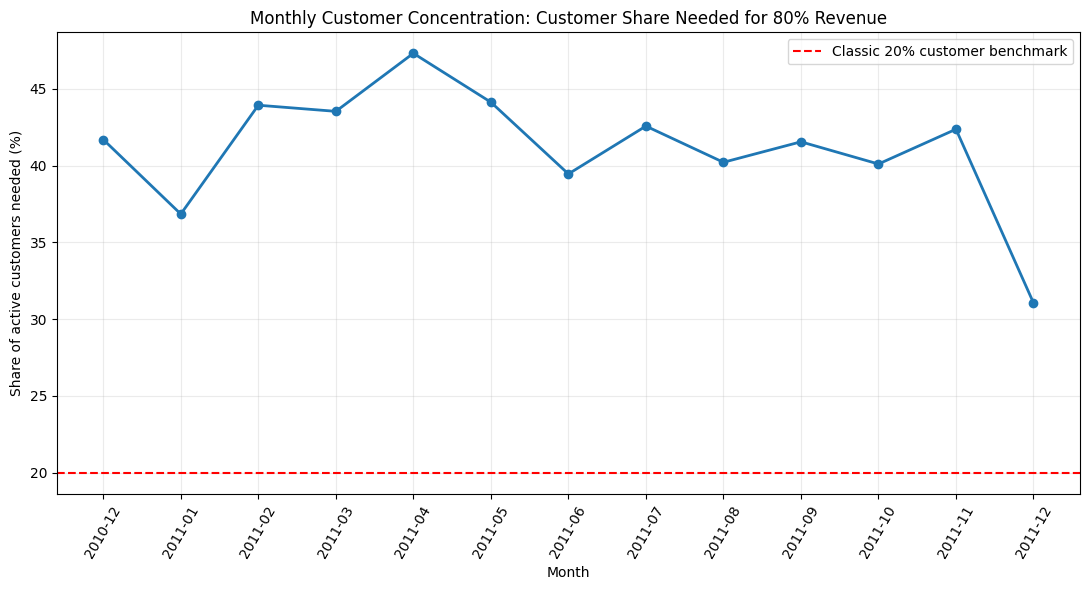

November–December monthly concentration:


,Month,Customers,CustomersFor80,CustomerShareFor80,RevenueShareAtCutoff,MonthlyRevenue
0,2010-12,885,369,0.416949,0.800287,572713.89
11,2011-11,1664,705,0.423678,0.800239,1161817.38
12,2011-12,615,191,0.310569,0.800697,518192.79


Monthly concentration range: 31.06% to 47.31%
Standard deviation across months: 3.97%


In [ ]:
monthly_rows = []
for month, mdf in customer_sales.groupby(customer_sales["InvoiceDate"].dt.to_period("M")):
    monthly_revenue = mdf.groupby("CustomerID")["Revenue"].sum()
    mp = pareto_table(monthly_revenue, "CustomerID")
    m80 = entities_for_target(mp)
    monthly_rows.append({
        "Month": str(month),
        "Customers": m80["total"],
        "CustomersFor80": m80["count"],
        "CustomerShareFor80": m80["share"],
        "RevenueShareAtCutoff": m80["revenue_share_reached"],
        "MonthlyRevenue": float(monthly_revenue.sum())
    })
monthly = pd.DataFrame(monthly_rows).sort_values("Month")
display(monthly)

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(monthly["Month"], monthly["CustomerShareFor80"]*100, marker="o", linewidth=2)
ax.axhline(20, color="red", linestyle="--", label="Classic 20% customer benchmark")
ax.set_title("Monthly Customer Concentration: Customer Share Needed for 80% Revenue")
ax.set_xlabel("Month")
ax.set_ylabel("Share of active customers needed (%)")
ax.tick_params(axis="x", rotation=60)
ax.legend()
fig.tight_layout()
fig.savefig("task4_monthly_concentration.png", dpi=180, bbox_inches="tight")
plt.show()

nov_dec = monthly[monthly["Month"].str.endswith("-11") | monthly["Month"].str.endswith("-12")]
print("November–December monthly concentration:")
display(nov_dec)
if not monthly.empty:
    print(f"Monthly concentration range: {monthly['CustomerShareFor80'].min():.2%} to {monthly['CustomerShareFor80'].max():.2%}")
    print(f"Standard deviation across months: {monthly['CustomerShareFor80'].std(ddof=1):.2%}")

## 8. Advanced Task 5 — Wholesale effect

In [ ]:
# Compute order value by customer and invoice, then each customer's average order value.
invoice_values = (customer_sales.groupby(["CustomerID", "InvoiceNo"], as_index=False)
                  .agg(OrderValue=("Revenue", "sum")))
customer_order_stats = (invoice_values.groupby("CustomerID")
                        .agg(TotalSpend=("OrderValue", "sum"),
                             InvoiceCount=("InvoiceNo", "nunique"),
                             AvgOrderValue=("OrderValue", "mean"))
                        .sort_values("TotalSpend", ascending=False))
top5_cutoff = customer_order_stats["TotalSpend"].quantile(0.95)
top5_spenders = customer_order_stats[customer_order_stats["TotalSpend"] >= top5_cutoff].copy()
median_avg_order = customer_order_stats["AvgOrderValue"].median()
wholesale_threshold = 10 * median_avg_order
suspected_wholesalers = customer_order_stats[customer_order_stats["AvgOrderValue"] > wholesale_threshold].copy()

print(f"Top-5% spend cutoff: £{top5_cutoff:,.2f} total spend")
print(f"Top 5% spenders identified: {len(top5_spenders):,} ({len(top5_spenders)/len(customer_order_stats):.2%} of customers)")
print(f"Median customer average order value: £{median_avg_order:,.2f}")
print(f"Suspected wholesaler threshold (>10× median): £{wholesale_threshold:,.2f} average order")
print(f"Suspected wholesalers identified: {len(suspected_wholesalers):,}")

# Baseline concentration across all customers
baseline_p = pareto_table(customer_order_stats["TotalSpend"], "CustomerID")
baseline_80 = entities_for_target(baseline_p)

# Exclude suspected wholesale customers and recalculate.
remaining_stats = customer_order_stats.drop(index=suspected_wholesalers.index)
filtered_p = pareto_table(remaining_stats["TotalSpend"], "CustomerID")
filtered_80 = entities_for_target(filtered_p)

comparison = pd.DataFrame([
    {"Scenario": "All customers", "Customers": baseline_80["total"], "CustomersFor80": baseline_80["count"],
     "ShareFor80": baseline_80["share"], "RevenueShareAtCutoff": baseline_80["revenue_share_reached"],
     "RevenueIncluded": float(customer_order_stats["TotalSpend"].sum())},
    {"Scenario": "Suspected wholesalers removed", "Customers": filtered_80["total"], "CustomersFor80": filtered_80["count"],
     "ShareFor80": filtered_80["share"], "RevenueShareAtCutoff": filtered_80["revenue_share_reached"],
     "RevenueIncluded": float(remaining_stats["TotalSpend"].sum())}
])
display(comparison)
print("Change in share of customers needed for 80%:",
      f"{(filtered_80['share'] - baseline_80['share'])*100:+.2f} percentage points")
display(suspected_wholesalers.head(10))


Top-5% spend cutoff: £5,841.84 total spend
Top 5% spenders identified: 217 (5.00% of customers)
Median customer average order value: £293.90
Suspected wholesaler threshold (>10× median): £2,939.00 average order
Suspected wholesalers identified: 25


,Scenario,Customers,CustomersFor80,ShareFor80,RevenueShareAtCutoff,RevenueIncluded
0,All customers,4338,1133,0.261180,0.800053,8911407.904
1,Suspected wholesalers removed,4313,1306,0.302805,0.800058,7475587.794


Change in share of customers needed for 80%: +4.16 percentage points


,TotalSpend,InvoiceCount,AvgOrderValue
CustomerID,,,
14646,280206.02,73,3838.438630
18102,259657.30,60,4327.621667
17450,194550.79,46,4229.365000
16446,168472.50,2,84236.250000
12415,124914.53,21,5948.310952
12346,77183.60,1,77183.600000
14096,65164.79,17,3833.222941
14088,50491.81,13,3883.985385
15749,44534.30,3,14844.766667


## 9. Hypothesis check against the classic 80/20 rule

In [ ]:
# Descriptive benchmark comparison (not a statistical hypothesis test by itself).
actual_customer_share = customer_80["share"]
if np.isclose(actual_customer_share, 0.20, atol=0.02):
    interpretation = "approximately conforms to the classic 80/20 benchmark"
elif actual_customer_share < 0.20:
    interpretation = "is more concentrated than the classic 80/20 benchmark (fewer than 20% of customers reach 80% revenue)"
else:
    interpretation = "is less concentrated than the classic 80/20 benchmark (more than 20% of customers are needed to reach 80% revenue)"
print(f"The customer revenue distribution {interpretation}.")
print("Interpretation should consider data cleaning choices, missing customer IDs, returns/cancellations, and the single retailer/time period.")


The customer revenue distribution is less concentrated than the classic 80/20 benchmark (more than 20% of customers are needed to reach 80% revenue).
Interpretation should consider data cleaning choices, missing customer IDs, returns/cancellations, and the single retailer/time period.


## 10. Generate a results-based memo (~500 words)

In [ ]:
def money(x):
    return f"£{x:,.2f}"

top5_text = "; ".join(
    f"{row.StockCode} ({row.Description}, {money(row.Revenue)})"
    for row in top5_products.itertuples(index=False)
)
monthly_min_row = monthly.loc[monthly["CustomerShareFor80"].idxmin()] if not monthly.empty else None
monthly_max_row = monthly.loc[monthly["CustomerShareFor80"].idxmax()] if not monthly.empty else None
nov_dec_text = ", ".join(
    f"{r.Month}: {r.CustomerShareFor80:.1%}" for r in nov_dec.itertuples(index=False)
) or "November/December months were not available in the cleaned data"

memo = f'''# Applied Pareto Analysis — Results Memo

## Purpose and method
This analysis applies Pareto analysis to the UCI Online Retail dataset, a real transaction record from a UK-based online retailer. Revenue was calculated as quantity multiplied by unit price. Cancelled invoices and rows with non-positive quantity or price were excluded to focus on positive completed sales. Customer analysis excludes records without a CustomerID. These choices make the calculations reproducible, but the findings depend on the cleaning rules.

## Customer concentration
The cleaned customer analysis includes {customer_80["total"]:,} customers. The top {customer_80["count"]:,} customers, representing {customer_80["share"]:.1%} of customers, account for at least 80% of customer-linked revenue (the cumulative share at the cutoff is {customer_80["revenue_share_reached"]:.1%}). Compared with the classic 80/20 rule, which suggests 20% of customers generate 80% of revenue, this result {interpretation}. This means the retailer's revenue is {'more concentrated among a smaller group of customers' if actual_customer_share < 0.20 else 'spread across a broader group of customers' if actual_customer_share > 0.20 else 'close to the classic benchmark'}. The 80/20 rule is a useful guideline rather than a law, so the observed ratio should be reported rather than forced to match the benchmark.

## Product concentration
The product analysis includes {product_80["total"]:,} StockCodes. The top {product_80["count"]:,} products ({product_80["share"]:.1%} of products) reach at least 80% of product revenue. The five highest-revenue products are: {top5_text}. These items may deserve close attention in stock planning and supplier coordination. Revenue ranking alone does not show profit margin, returns, stock availability, or whether a product is strategically important, so those measures should be checked before making inventory decisions.

## Country concentration
The analysis covers {country_80["total"]} countries. The top {country_80["count"]} countries are needed to reach at least 80% of positive sales revenue. The United Kingdom contributes {uk_share:.1%} of total revenue ({money(uk_revenue)} out of {money(all_country_revenue)}). This indicates how strongly sales depend on the domestic market relative to international customers. The country ranking can help focus market planning, but it does not explain why customers in one country spend more.

## Monthly stability
Across the months available after cleaning, the share of active customers needed to reach 80% of monthly revenue ranges from {monthly["CustomerShareFor80"].min():.1%} to {monthly["CustomerShareFor80"].max():.1%}. The least concentrated month is {monthly_min_row["Month"] if monthly_min_row is not None else "not available"} and the most concentrated month is {monthly_max_row["Month"] if monthly_max_row is not None else "not available"}. November–December values are {nov_dec_text}. This comparison shows whether concentration is stable or changes during the seasonal peak; monthly differences may reflect customer mix, purchasing volume, and the number of active customers.

## Wholesale effect and recommendations
The top 5% spenders are identified using total customer spend. Suspected wholesalers are flagged when their average invoice value exceeds ten times the median customer average invoice value. Removing these flagged customers changes the share of customers needed for 80% from {baseline_80["share"]:.1%} to {filtered_80["share"]:.1%}, a shift of {(filtered_80["share"]-baseline_80["share"])*100:+.1f} percentage points. This is only a proxy for wholesale behaviour, not a verified customer classification. The retailer should monitor high-value customers, protect availability of leading products, and assess country and monthly patterns regularly. A follow-up analysis of gross margin, repeat purchasing, and customer retention would help convert revenue concentration into more reliable business decisions.
'''
with open("stage2_500_word_memo.md", "w", encoding="utf-8") as f:
    f.write(memo)
print(memo)
print("\nSaved memo to stage2_500_word_memo.md")

# Applied Pareto Analysis — Results Memo

## Purpose and method
This analysis applies Pareto analysis to the UCI Online Retail dataset, a real transaction record from a UK-based online retailer. Revenue was calculated as quantity multiplied by unit price. Cancelled invoices and rows with non-positive quantity or price were excluded to focus on positive completed sales. Customer analysis excludes records without a CustomerID. These choices make the calculations reproducible, but the findings depend on the cleaning rules.

## Customer concentration
The cleaned customer analysis includes 4,338 customers. The top 1,133 customers, representing 26.1% of customers, account for at least 80% of customer-linked revenue (the cumulative share at the cutoff is 80.0%). Compared with the classic 80/20 rule, which suggests 20% of customers generate 80% of revenue, this result is less concentrated than the classic 80/20 benchmark (more than 20% of customers are needed to reach 80% revenue). This means 

## 11. Export summary tables
The notebook exports tables for submission. Keep the raw dataset separate; it is available from UCI under CC BY 4.0.

In [ ]:
customer_pareto.to_csv("customer_pareto.csv")
product_pareto.to_csv("product_pareto.csv")
country_pareto.to_csv("country_pareto.csv")
monthly.to_csv("monthly_concentration.csv", index=False)
top5_products.to_csv("top5_products.csv", index=False)
comparison.to_csv("wholesale_comparison.csv", index=False)
print("Exported result tables and charts to the current working directory.")

Exported result tables and charts to the current working directory.
